# Thí nghiệm tiền xử lý House Prices — Phúc

In [1]:
from pathlib import Path
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

project = next(p for p in (Path.cwd(), *Path.cwd().parents)
               if (p / "src" / "prepare_data.py").is_file())
sys.path.insert(0, str(project))
from src.prepare_data import DATA_DIR, OUTPUT_DIR, extract_features, main as prepare_data

raw_train = pd.read_csv(DATA_DIR / "raw/train.csv")
raw_test = pd.read_csv(DATA_DIR / "raw/test.csv")
X_raw = extract_features(raw_train)
X_test_raw = extract_features(raw_test)
missing = pd.DataFrame({
    "Train thiếu": X_raw.isna().sum(),
    "Test thiếu": X_test_raw.isna().sum(),
    "Train (%)": X_raw.isna().mean() * 100,
    "Test (%)": X_test_raw.isna().mean() * 100,
})
missing = missing.loc[missing[["Train thiếu", "Test thiếu"]].sum(axis=1) > 0]
missing = missing.sort_values("Train thiếu", ascending=False)
print(missing.round(2).to_string())

              Train thiếu  Test thiếu  Train (%)  Test (%)
PoolQC               1453        1456      99.52     99.79
MiscFeature          1406        1408      96.30     96.50
Alley                1369        1352      93.77     92.67
Fence                1179        1169      80.75     80.12
MasVnrType            872         894      59.73     61.27
FireplaceQu           690         730      47.26     50.03
LotFrontage           259         227      17.74     15.56
GarageType             81          76       5.55      5.21
GarageYrBlt            81          78       5.55      5.35
GarageFinish           81          78       5.55      5.35
GarageQual             81          78       5.55      5.35
GarageCond             81          78       5.55      5.35
BsmtFinType2           38          42       2.60      2.88
BsmtExposure           38          44       2.60      3.02
BsmtFinType1           37          42       2.53      2.88
BsmtCond               37          45       2.53      3.

## Chuyển dữ liệu gốc sang dữ liệu dùng cho mô hình

Gọi trực tiếp `src/prepare_data.py` để ghi hai CSV trong `data/processed`. Script học trung vị, trung bình, độ lệch chuẩn và danh mục từ train rồi áp dụng cho test. `Id` giữ để đối chiếu và `SalePrice` giữ nguyên làm biến mục tiêu của train.

In [2]:
prepare_data()
train = pd.read_csv(OUTPUT_DIR / "train_processed.csv")
test = pd.read_csv(OUTPUT_DIR / "test_processed.csv")
assert train.drop(columns="SalePrice").columns.equals(test.columns)
for raw, processed in ((raw_train, train), (raw_test, test)):
    pd.testing.assert_series_equal(raw["Id"], processed["Id"])
    assert np.isfinite(processed.to_numpy()).all()
pd.testing.assert_series_equal(raw_train["SalePrice"], train["SalePrice"])

summary = pd.DataFrame([
    ["Train", len(train), X_raw.shape[1], train.shape[1] - 2, X_raw.isna().sum().sum(), 0],
    ["Test", len(test), X_test_raw.shape[1], test.shape[1] - 1, X_test_raw.isna().sum().sum(), 0],
], columns=["Tập", "Số dòng", "Đặc trưng gốc", "Đặc trưng sau xử lý", "Ô thiếu trước", "Ô thiếu sau"])
print(summary.to_string(index=False))

data\processed\train_processed.csv: 1460 rows, 319 columns
data\processed\test_processed.csv: 1459 rows, 318 columns
  Tập  Số dòng  Đặc trưng gốc  Đặc trưng sau xử lý  Ô thiếu trước  Ô thiếu sau
Train     1460             79                  317           7829            0
 Test     1459             79                  317           7878            0


## Vì sao điền thiếu và chuẩn hóa như vậy?

- **Trung vị cho cột số.** Trung vị ít nhạy với giá trị cực đoan. Tuy nhiên, một trung vị chung có thể che khuất khác biệt giữa các khu phố. Với `GarageYrBlt`, điền trung vị cho nhà không có garage tạo ra một năm xây giả.
- **StandardScaler cho cột số.** Sau khi điền thiếu, script trừ trung bình và chia độ lệch chuẩn học từ train. Thang đo tương đương giúp Ridge áp dụng mức phạt L2 dễ so sánh hơn giữa các cột. Phép biến đổi vẫn nhạy với ngoại lệ và thường không cần thiết cho mô hình cây.
- **Missing và one-hot cho cột phân loại.** Nhãn riêng giữ tín hiệu thiếu, còn one-hot tránh áp đặt thứ tự lên các nhóm, kể cả mã số `MSSubClass`. Nhóm mới ở test có các cột one-hot tương ứng bằng 0.
- **Đọc ý nghĩa giá trị NA.** Theo `data/raw/data_description.txt`, NA ở `PoolQC` nghĩa là không có hồ bơi. Cột này có 1.453 dòng train mang giá trị thiếu sau khi đọc CSV. Tương tự, nhiều cột garage và tầng hầm dùng NA để biểu thị nhà không có tiện ích.

In [3]:
column = "LotFrontage"
median = raw_train[column].median()
filled = raw_train[column].fillna(median)
i = raw_train.index[raw_train[column].isna()][0]
expected = (filled - filled.mean()) / filled.std(ddof=0)
np.testing.assert_allclose(train[column], expected)
example = pd.DataFrame([[train.at[i, "Id"], median, filled.mean(), filled.std(ddof=0), train.at[i, column]]],
                       columns=["Id", "Trung vị điền", "Trung bình sau điền", "Độ lệch chuẩn", "Z-score"])
print(example.round(4).to_string(index=False))

 Id  Trung vị điền  Trung bình sau điền  Độ lệch chuẩn  Z-score
  8           69.0              69.8637        22.0201  -0.0392


## Tương quan Pearson trên tập train gốc

10/10 đặc trưng có Pearson dương. OverallQual cao nhất (r=0.791).


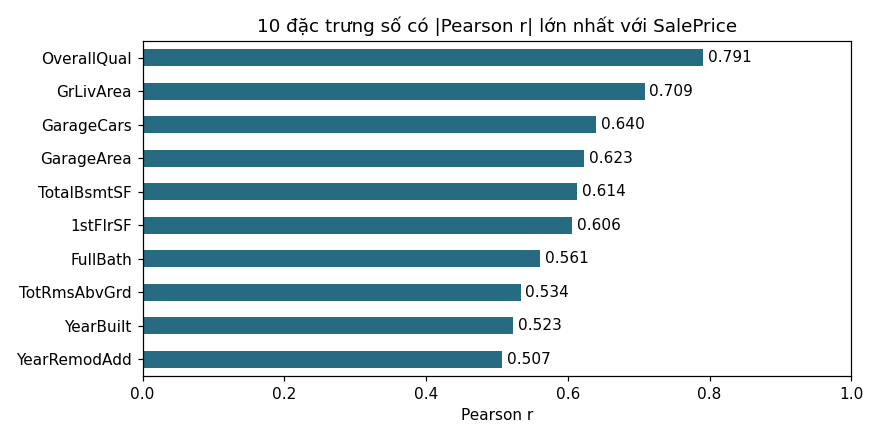

In [4]:
r = X_raw.select_dtypes(include="number").corrwith(raw_train["SalePrice"]).dropna()
top = r.loc[r.abs().nlargest(10).index]
ax = top.iloc[::-1].plot.barh(figsize=(8, 4), color="#266b82")
ax.bar_label(ax.containers[0], fmt="%.3f", padding=3)
ax.set(xlim=(min(0, top.min() - .1), 1), xlabel="Pearson r",
       title="10 đặc trưng số có |Pearson r| lớn nhất với SalePrice")
plt.tight_layout()
plt.show()
print(f"{top.gt(0).sum()}/10 đặc trưng có Pearson dương. "
      f"{top.index[0]} cao nhất (r={top.iloc[0]:.3f}).")

## Cấu hình tiền xử lý nên thử

| Thay đổi | Giả thuyết cần kiểm tra |
|---|---|
| Tách `NoGarage`, `NoBasement` và `Unknown` | Phân biệt nhà không có tiện ích với dữ liệu chưa được ghi nhận. Chỉ điền 0 cho diện tích hoặc số lượng khi xác nhận tiện ích không tồn tại. |
| Điền `LotFrontage` theo trung vị `Neighborhood` | Giữ khác biệt giữa các khu phố. Dùng trung vị toàn train nếu không có trung vị cho khu phố đó. |
| Dùng `RobustScaler` cho Ridge, hoặc bỏ scaler cho Random Forest | Kiểm tra độ nhạy với ngoại lệ và mức cần thiết của chuẩn hóa. |
| Giữ một trong `GarageCars` và `GarageArea` | Kiểm tra hai cột cùng mô tả quy mô garage có bổ sung thông tin cho nhau hay không. Pearson chỉ đo liên hệ tuyến tính từng cột với giá. |

Khi đánh giá các cấu hình, thay từng bước, giữ cùng mô hình và cách chia fold. Fit tiền xử lý riêng trong từng fold trước khi đo RMSE trên log giá.